# Hypothesis Testing: Python Examples

Examples using SciPy. Interpret test results with effect sizes, uncertainty, design, and assumptions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
print('NumPy:', np.__version__)


NumPy: 2.3.5


## 1. One-sample t-test

In [2]:
sample = np.array([51, 49, 52, 48, 50, 53, 47, 51], dtype=float)
result = stats.ttest_1samp(sample, popmean=50)
print('Sample mean:', round(float(sample.mean()), 3))
print('t statistic:', round(float(result.statistic), 4))
print('p-value:', round(float(result.pvalue), 4))


Sample mean: 50.125
t statistic: 0.1741
p-value: 0.8667


## 2. Welch's independent two-sample t-test

In [3]:
group_a = np.array([12, 14, 13, 15, 11], dtype=float)
group_b = np.array([10, 9, 12, 11, 8], dtype=float)
result = stats.ttest_ind(group_a, group_b, equal_var=False)
print('Mean difference (A - B):', round(float(group_a.mean() - group_b.mean()), 3))
print('t statistic:', round(float(result.statistic), 4))
print('p-value:', round(float(result.pvalue), 4))


Mean difference (A - B): 3.0
t statistic: 3.0
p-value: 0.0171


## 3. Paired t-test

In [4]:
before = np.array([10, 12, 9, 14, 11], dtype=float)
after = np.array([11, 13, 10, 15, 12], dtype=float)
print('Mean paired change:', float((after-before).mean()))
print(stats.ttest_rel(after, before))


Mean paired change: 1.0
TtestResult(statistic=np.float64(inf), pvalue=np.float64(0.0), df=np.int64(4))


/opt/pyvenv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


## 4. Chi-square test of independence

In [5]:
table = np.array([[30, 20], [15, 35]])
chi2, p_value, dof, expected = stats.chi2_contingency(table)
print('Chi-square:', round(float(chi2), 4), 'p-value:', round(float(p_value), 4), 'df:', dof)
print('Expected counts:\n', expected)


Chi-square: 7.9192 p-value: 0.0049 df: 1
Expected counts:
 [[22.5 27.5]
 [22.5 27.5]]


## 5. Pearson correlation

In [6]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 5, 4, 6], dtype=float)
r, p_value = stats.pearsonr(x, y)
print('Pearson r:', round(float(r), 4), 'p-value:', round(float(p_value), 4))


Pearson r: 0.8528 p-value: 0.0663


## 6. Visualize sample data and its mean

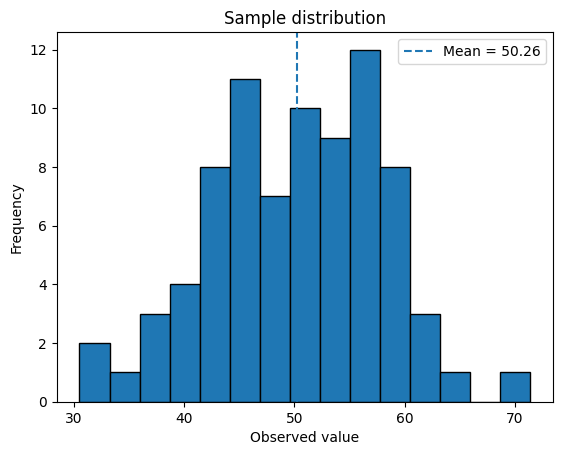

In [7]:
sample = rng.normal(loc=50, scale=10, size=80)
plt.hist(sample, bins=15, edgecolor='black')
plt.axvline(sample.mean(), linestyle='--', label=f'Mean = {sample.mean():.2f}')
plt.xlabel('Observed value')
plt.ylabel('Frequency')
plt.title('Sample distribution')
plt.legend()
plt.show()


## 7. One-sided versus two-sided alternatives

Choose the alternative from the research question before analyzing the data.

In [8]:
x = np.array([53, 54, 49, 52, 55, 51, 54, 52], dtype=float)
# Two-sided test against mean 50
print('Two-sided:', stats.ttest_1samp(x, popmean=50, alternative='two-sided'))
# One-sided test for a mean greater than 50
print('Greater-than:', stats.ttest_1samp(x, popmean=50, alternative='greater'))


Two-sided: TtestResult(statistic=np.float64(3.668996928526714), pvalue=np.float64(0.007974815912587955), df=np.int64(7))
Greater-than: TtestResult(statistic=np.float64(3.668996928526714), pvalue=np.float64(0.003987407956293977), df=np.int64(7))


## 8. Bonferroni multiple-testing illustration

In [9]:
p_values = np.array([0.01, 0.03, 0.04, 0.20, 0.50])
alpha = 0.05
threshold = alpha / len(p_values)
print('Unadjusted significant tests:', int((p_values < alpha).sum()))
print('Bonferroni threshold:', threshold)
print('Bonferroni significant tests:', int((p_values < threshold).sum()))


Unadjusted significant tests: 3
Bonferroni threshold: 0.01
Bonferroni significant tests: 0


## Key takeaways

- Define hypotheses and test direction before viewing results.
- A p-value is not the probability that a hypothesis is true.
- Report effect estimates and uncertainty alongside test results.
- Check assumptions and consider multiple testing.